# Training Sample 2 — Exploratory Data Analysis (EDA)

## Project Overview
This notebook analyzes the `TrainingSample2.xlsx` dataset, which contains geographic, customer, business segment, product, date, pricing, and order-quantity fields.

**Workflow:** setup and loading → structure → data quality → derived fields → categorical breakdowns → overall metrics → date trends → geography → customer and segment analysis → product analysis → relationships and validation → summary.

**Calculated metric note:** The source has `UnitPrice` and `OrderQty`, but no explicit sales/revenue column. Therefore, this notebook calculates **Estimated Sales = UnitPrice × OrderQty** for analysis. This is a derived estimate from the provided fields, not a source-reported sales measure.

## 1. Setup & Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

sns.set_theme()
plt.rcParams["figure.figsize"] = (10, 5)

file_path = Path("TrainingSample2.xlsx")

# In Google Colab, upload the workbook if it is not already available.
if not file_path.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        uploaded_name = next((name for name in uploaded if name.lower().endswith((".xlsx", ".xls"))), None)
        if uploaded_name:
            file_path = Path(uploaded_name)
    except ImportError:
        pass

if not file_path.exists():
    raise FileNotFoundError(
        "TrainingSample2.xlsx was not found. Place it beside this notebook or upload it in Google Colab."
    )

df = pd.read_excel(file_path, sheet_name="TrainingSample2")
df.head()

,Region,SubRegion,Market,Customer,Business Segment,Category,Model,Color,SalesDate,ListPrice,UnitPrice,OrderQty
0,North America,United States,Southeast,Trusted Catalog Store,Bikes,Mountain Bikes,Mountain-100,Silver,2018-11-10,3399.99,2039.99,3
1,North America,United States,Southeast,Trusted Catalog Store,Bikes,Mountain Bikes,Mountain-100,Black,2019-02-25,3374.99,2024.99,2
2,North America,United States,Southeast,Trusted Catalog Store,Bikes,Mountain Bikes,Mountain-100,Black,2019-10-01,3374.99,2024.99,3
3,North America,United States,Southeast,Trusted Catalog Store,Clothing,Socks,Mountain Bike Socks,White,2020-05-21,9.50,5.70,8
4,North America,United States,Southeast,Trusted Catalog Store,Bikes,Mountain Bikes,Mountain-100,Silver,2019-11-29,3399.99,2039.99,1


## 2. Basic Structure

In [2]:
print("Dataset shape:", df.shape)
print("\\nColumns:")
print(df.columns.tolist())

print("\\nData types and non-null counts:")
df.info()

print("\\nSample records:")
display(df.sample(min(5, len(df)), random_state=42))

Dataset shape: (60919, 12)
\nColumns:
['Region', 'SubRegion', 'Market', 'Customer', 'Business Segment', 'Category', 'Model', 'Color', 'SalesDate', 'ListPrice', 'UnitPrice', 'OrderQty']
\nData types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60919 entries, 0 to 60918
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Region            60919 non-null  object        
 1   SubRegion         60919 non-null  object        
 2   Market            60919 non-null  object        
 3   Customer          60919 non-null  object        
 4   Business Segment  60919 non-null  object        
 5   Category          60919 non-null  object        
 6   Model             60919 non-null  object        
 7   Color             55693 non-null  object        
 8   SalesDate         60919 non-null  datetime64[ns]
 9   ListPrice         60919 non-null  float64       
 10  UnitPrice         6

,Region,SubRegion,Market,Customer,Business Segment,Category,Model,Color,SalesDate,ListPrice,UnitPrice,OrderQty
2980,North America,United States,Southwest,Totes & Baskets Company,Bikes,Road Bikes,Road-650,Red,2019-04-28,782.99,419.46,3
12955,North America,United States,Southwest,Mountain Bike Center,Components,Wheels,HL Road Front Wheel,Black,2020-05-27,330.06,198.04,6
6920,North America,United States,Northwest,Sure & Reliable Sporting Goods,Bikes,Road Bikes,Road-650,Red,2020-12-02,782.99,234.90,1
37446,North America,United States,Central,First Bike Store,Bikes,Road Bikes,Road-750,Black,2021-01-03,539.99,323.99,3
19077,North America,United States,Southeast,eCommerce Bikes,Components,Mountain Frames,HL Mountain Frame,Silver,2021-08-21,1364.50,744.27,1


In [3]:
print("Numeric summary:")
display(df.describe().T)

print("Categorical summary:")
display(df.describe(include="object").T)

Numeric summary:


,count,mean,min,25%,50%,75%,max,std
SalesDate,60919,2021-05-09 02:18:38.193010688,2018-06-18 00:00:00,2020-08-03 00:00:00,2021-05-12 00:00:00,2022-02-20 00:00:00,2024-02-26 00:00:00,NaN
ListPrice,60919.0,771.3183,2.29,59.99,364.09,1120.49,3578.27,897.975292
UnitPrice,60919.0,444.277993,1.33,34.93,209.26,672.29,2146.96,519.851905
OrderQty,60919.0,3.521332,1.0,2.0,3.0,4.0,44.0,3.032399


Categorical summary:


,count,unique,top,freq
Region,60919,3,North America,50253
SubRegion,60919,6,United States,38809
Market,60919,10,Southwest,13379
Customer,60919,633,Vigorous Exercise Company,530
Business Segment,60919,4,Bikes,24826
Category,60919,33,Road Bikes,12876
Model,60919,93,Road-650,5358
Color,55693,8,Black,20256


## 3. Data Quality Checks

In [4]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percent": (df.isna().mean() * 100).round(2)
}).sort_values("Missing Count", ascending=False)
display(missing_summary)

print("Exact duplicate rows:", df.duplicated().sum())
print("Missing SalesDate values before conversion:", df["SalesDate"].isna().sum())

df["SalesDate"] = pd.to_datetime(df["SalesDate"], errors="coerce")
print("Invalid/missing SalesDate values after conversion:", df["SalesDate"].isna().sum())

for col in ["ListPrice", "UnitPrice", "OrderQty"]:
    print(f"Negative values in {col}:", (df[col] < 0).sum())

print("Zero OrderQty values:", (df["OrderQty"] == 0).sum())

,Missing Count,Missing Percent
Color,5226,8.58
Region,0,0.00
Market,0,0.00
SubRegion,0,0.00
Customer,0,0.00
Business Segment,0,0.00
Category,0,0.00
Model,0,0.00
SalesDate,0,0.00
ListPrice,0,0.00


Exact duplicate rows: 34
Missing SalesDate values before conversion: 0
Invalid/missing SalesDate values after conversion: 0
Negative values in ListPrice: 0
Negative values in UnitPrice: 0
Negative values in OrderQty: 0
Zero OrderQty values: 0


## 4. Derived Fields

In [5]:
# Derived fields for analysis; original columns are preserved.
df["Estimated Sales"] = df["UnitPrice"] * df["OrderQty"]
df["List Value"] = df["ListPrice"] * df["OrderQty"]
df["Unit Discount"] = df["ListPrice"] - df["UnitPrice"]
df["Discount Percent"] = np.where(
    df["ListPrice"] != 0,
    (df["ListPrice"] - df["UnitPrice"]) / df["ListPrice"] * 100,
    np.nan
)

df["Year"] = df["SalesDate"].dt.year
df["Quarter"] = df["SalesDate"].dt.to_period("Q").astype("string")
df["Month Number"] = df["SalesDate"].dt.month
df["Month"] = df["SalesDate"].dt.month_name()
df["Year-Month"] = df["SalesDate"].dt.to_period("M").astype("string")
df["Day of Week"] = df["SalesDate"].dt.day_name()
df["Is Weekend"] = df["SalesDate"].dt.dayofweek >= 5

display(df[["SalesDate", "Year", "Quarter", "Month", "Year-Month",
            "UnitPrice", "OrderQty", "Estimated Sales",
            "Unit Discount", "Discount Percent"]].head())

,SalesDate,Year,Quarter,Month,Year-Month,UnitPrice,OrderQty,Estimated Sales,Unit Discount,Discount Percent
0,2018-11-10,2018,2018Q4,November,2018-11,2039.99,3,6119.97,1360.0,40.000118
1,2019-02-25,2019,2019Q1,February,2019-02,2024.99,2,4049.98,1350.0,40.000119
2,2019-10-01,2019,2019Q4,October,2019-10,2024.99,3,6074.97,1350.0,40.000119
3,2020-05-21,2020,2020Q2,May,2020-05,5.70,8,45.60,3.8,40.000000
4,2019-11-29,2019,2019Q4,November,2019-11,2039.99,1,2039.99,1360.0,40.000118


## 5. Categorical Breakdowns

In [6]:
categorical_cols = [
    "Region", "SubRegion", "Market", "Customer",
    "Business Segment", "Category", "Model", "Color"
]

for col in categorical_cols:
    print(f"\\n{col}: {df[col].nunique(dropna=True)} unique non-missing values")
    display(df[col].value_counts(dropna=False).head(15).rename("Record Count").to_frame())

\nRegion: 3 unique non-missing values


,Record Count
Region,
North America,50253
Europe,8953
Pacific,1713


\nSubRegion: 6 unique non-missing values


,Record Count
SubRegion,
United States,38809
Canada,11444
France,3530
United Kingdom,3520
Germany,1903
Australia,1713


\nMarket: 10 unique non-missing values


...

,Record Count
Category,
Road Bikes,12876
Mountain Bikes,7487
Road Frames,4713
Mountain Frames,4477
Touring Bikes,4463
Jerseys,3859
Helmets,2740
Gloves,2175
Wheels,1904


\nModel: 93 unique non-missing values


,Record Count
Model,
Road-650,5358
Mountain-200,3124
Sport-100,2740
Long-Sleeve Logo Jersey,2622
LL Road Frame,2527
Road-250,2248
Touring-3000,1903
HL Mountain Frame,1899
Road-550-W,1888


\nColor: 8 unique non-missing values


,Record Count
Color,
Black,20256
Red,8116
Yellow,8063
Silver,7230
NaN,5226
Blue,5074
Multi,4576
Silver/Black,1517
White,861


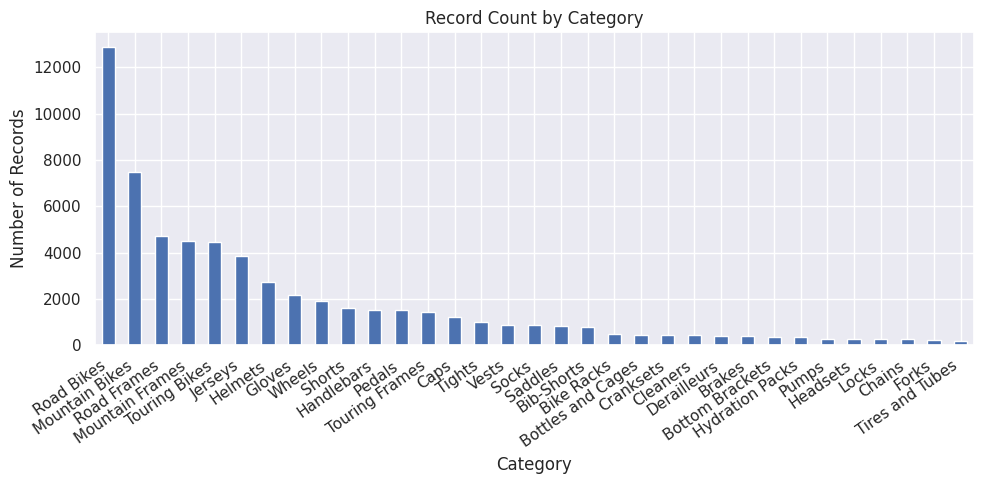

In [7]:
df["Category"].value_counts().plot(kind="bar")
plt.title("Record Count by Category")
plt.xlabel("Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 6. Overall Business Metrics

In [8]:
total_estimated_sales = df["Estimated Sales"].sum()
total_list_value = df["List Value"].sum()
total_discount_value = df["Unit Discount"].mul(df["OrderQty"]).sum()

kpis = pd.Series({
    "Rows / Records": len(df),
    "Unique Customers": df["Customer"].nunique(),
    "Unique Models": df["Model"].nunique(),
    "Total Order Quantity": df["OrderQty"].sum(),
    "Estimated Sales (UnitPrice × OrderQty)": total_estimated_sales,
    "List Value (ListPrice × OrderQty)": total_list_value,
    "Estimated Discount Value": total_discount_value,
    "Weighted Discount (%)": (total_discount_value / total_list_value * 100)
        if total_list_value != 0 else np.nan,
    "Average Unit Price": df["UnitPrice"].mean(),
    "Average Order Quantity per Record": df["OrderQty"].mean()
})
display(kpis.to_frame("Value").round(2))

,Value
Rows / Records,6.091900e+04
Unique Customers,6.330000e+02
Unique Models,9.300000e+01
Total Order Quantity,2.145160e+05
Estimated Sales (UnitPrice × OrderQty),8.101483e+07
List Value (ListPrice × OrderQty),1.410773e+08
Estimated Discount Value,6.006247e+07
Weighted Discount (%),4.257000e+01
Average Unit Price,4.442800e+02
Average Order Quantity per Record,3.520000e+00


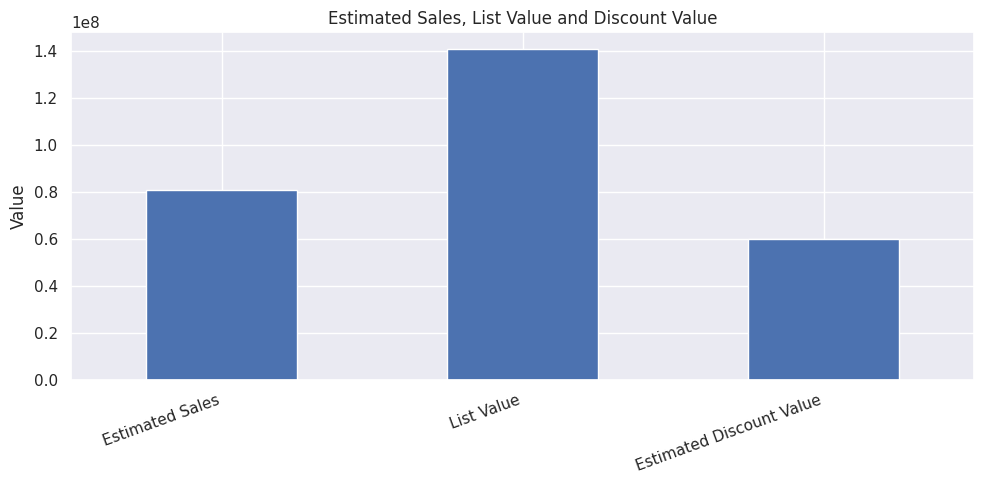

In [9]:
metric_values = pd.Series({
    "Estimated Sales": df["Estimated Sales"].sum(),
    "List Value": df["List Value"].sum(),
    "Estimated Discount Value": df["Unit Discount"].mul(df["OrderQty"]).sum()
})
metric_values.plot(kind="bar")
plt.title("Estimated Sales, List Value and Discount Value")
plt.ylabel("Value")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 7. Date & Time Trend Analysis

,Year-Month,Estimated_Sales,Order_Quantity,Records,Average_Unit_Price
0,2018-06,18888.68,13,6,1338.765000
1,2018-07,20611.19,26,13,968.360000
2,2018-08,98192.48,108,39,873.140000
3,2018-09,146965.91,204,74,860.851486
4,2018-10,218952.70,274,107,798.915140


,Year-Month,Estimated_Sales,Order_Quantity,Records,Average_Unit_Price
64,2023-10,244265.34,239,103,925.018447
65,2023-11,154868.76,221,81,662.756790
66,2023-12,107539.71,191,69,671.020290
67,2024-01,110195.93,125,47,785.100213
68,2024-02,28532.74,29,10,881.703000


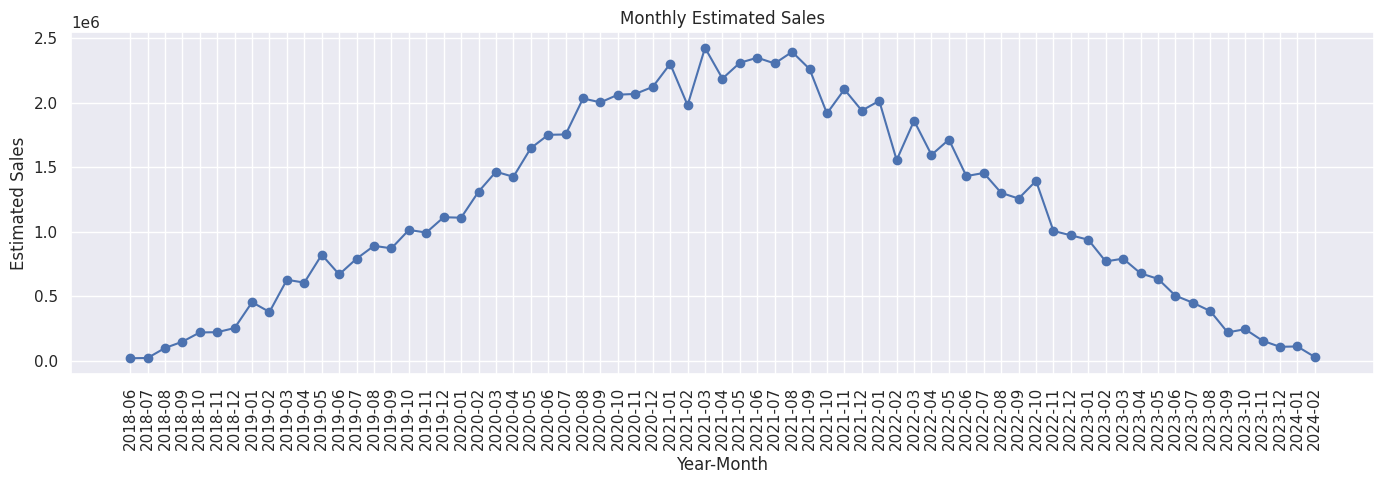

In [10]:
monthly = (
    df.dropna(subset=["SalesDate"])
      .groupby("Year-Month", as_index=False)
      .agg(Estimated_Sales=("Estimated Sales", "sum"),
           Order_Quantity=("OrderQty", "sum"),
           Records=("SalesDate", "size"),
           Average_Unit_Price=("UnitPrice", "mean"))
      .sort_values("Year-Month")
)
display(monthly.head())
display(monthly.tail())

plt.figure(figsize=(14, 5))
plt.plot(monthly["Year-Month"], monthly["Estimated_Sales"], marker="o")
plt.title("Monthly Estimated Sales")
plt.xlabel("Year-Month")
plt.ylabel("Estimated Sales")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

,Year,Estimated_Sales,Order_Quantity,Records,Average_Unit_Price
0,2018,977635.26,1372,527,791.51
1,2019,9226391.37,21590,6375,482.72
2,2020,20756277.08,58302,16068,424.79
3,2021,26479393.74,72940,20325,425.38
4,2022,17561092.32,47904,13731,433.28
5,2023,5875308.58,12254,3836,548.49
6,2024,138728.67,154,57,802.05


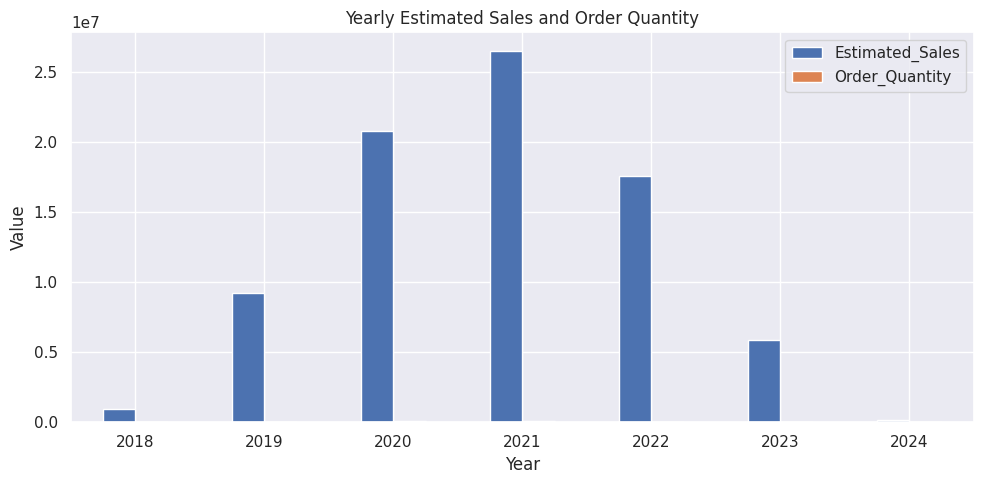

In [11]:
yearly = (
    df.groupby("Year", dropna=False)
      .agg(Estimated_Sales=("Estimated Sales", "sum"),
           Order_Quantity=("OrderQty", "sum"),
           Records=("SalesDate", "size"),
           Average_Unit_Price=("UnitPrice", "mean"))
      .reset_index()
)
display(yearly.round(2))

yearly.set_index("Year")[["Estimated_Sales", "Order_Quantity"]].plot(kind="bar")
plt.title("Yearly Estimated Sales and Order Quantity")
plt.xlabel("Year")
plt.ylabel("Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,Estimated_Sales,Order_Quantity,Records
Day of Week,,,
Monday,11752587.63,31033,8784
Tuesday,11746949.72,31672,8821
Wednesday,11558482.69,30541,8679
Thursday,11196382.90,30314,8626
Friday,11610427.51,30242,8723
Saturday,11265123.75,29950,8517
Sunday,11884872.82,30764,8769


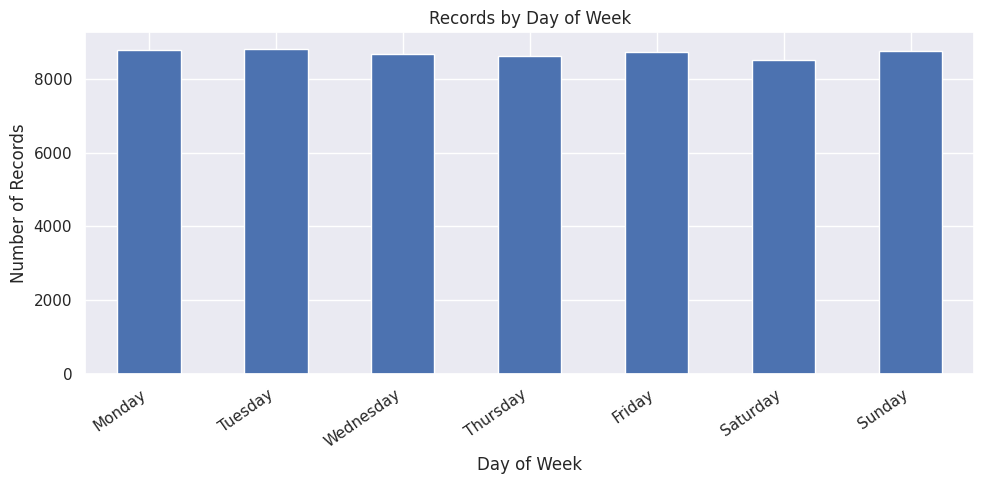

In [12]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_summary = (
    df.groupby("Day of Week", dropna=False)
      .agg(Estimated_Sales=("Estimated Sales", "sum"),
           Order_Quantity=("OrderQty", "sum"),
           Records=("SalesDate", "size"))
      .reindex(weekday_order)
)
display(weekday_summary.round(2))

weekday_summary["Records"].plot(kind="bar")
plt.title("Records by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Records")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 8. Geographic Analysis

\nPerformance by Region


,Estimated_Sales,Order_Quantity,Records,Average_Unit_Price
Region,,,,
North America,68381907.94,174509,50253,455.74
Europe,11010058.46,35059,8953,379.21
Pacific,1622860.62,4948,1713,448.18


\nPerformance by SubRegion


,Estimated_Sales,Order_Quantity,Records,Average_Unit_Price
SubRegion,,,,
United States,53918701.38,132748,38809,464.67
Canada,14463206.56,41761,11444,425.46
France,4647425.41,14348,3530,372.78
United Kingdom,4311100.54,13193,3520,391.25
Germany,2051532.51,7518,1903,368.87
Australia,1622860.62,4948,1713,448.18


\nPerformance by Market


,Estimated_Sales,Order_Quantity,Records,Average_Unit_Price
Market,,,,
Southwest,18597946.59,46840,13379,452.53
Canada,14463206.56,41761,11444,425.46
Northwest,12523013.78,27783,7872,499.16
Central,7932816.17,19473,5812,461.08
Southeast,7908283.37,18836,5937,487.43
Northeast,6956641.47,19816,5809,426.19
France,4647425.41,14348,3530,372.78
United Kingdom,4311100.54,13193,3520,391.25
Germany,2051532.51,7518,1903,368.87


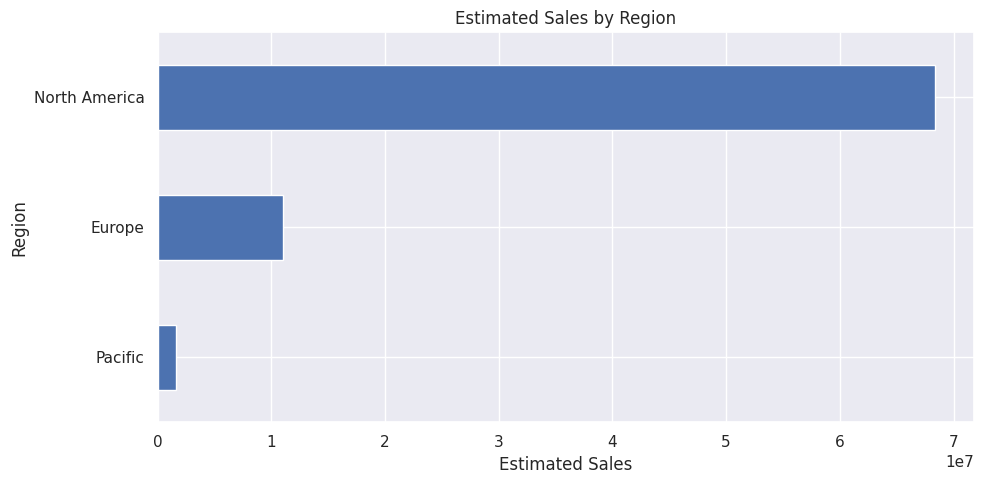

In [13]:
for geo_col in ["Region", "SubRegion", "Market"]:
    summary = (
        df.groupby(geo_col, dropna=False)
          .agg(Estimated_Sales=("Estimated Sales", "sum"),
               Order_Quantity=("OrderQty", "sum"),
               Records=("OrderQty", "size"),
               Average_Unit_Price=("UnitPrice", "mean"))
          .sort_values("Estimated_Sales", ascending=False)
    )
    print(f"\\nPerformance by {geo_col}")
    display(summary.round(2))

region_sales = df.groupby("Region")["Estimated Sales"].sum().sort_values()
region_sales.plot(kind="barh")
plt.title("Estimated Sales by Region")
plt.xlabel("Estimated Sales")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

## 9. Customer & Business Segment Analysis

,Estimated_Sales,Order_Quantity,Records,Average_Unit_Price
Customer,,,,
Brakes and Gears,882273.53,1558,298,563.29
Vigorous Exercise Company,860142.25,2737,530,373.58
Excellent Riding Supplies,853848.29,1322,366,632.39
Totes & Baskets Company,817125.03,1736,436,517.16
Retail Mall,803767.27,1931,451,420.34
Corner Bicycle Supply,787806.32,1708,429,532.80
Outdoor Equipment Store,751629.56,1688,332,417.32
Thorough Parts and Repair Services,741360.41,1344,358,590.69
"Health Spa, Limited",735233.10,1408,352,508.05


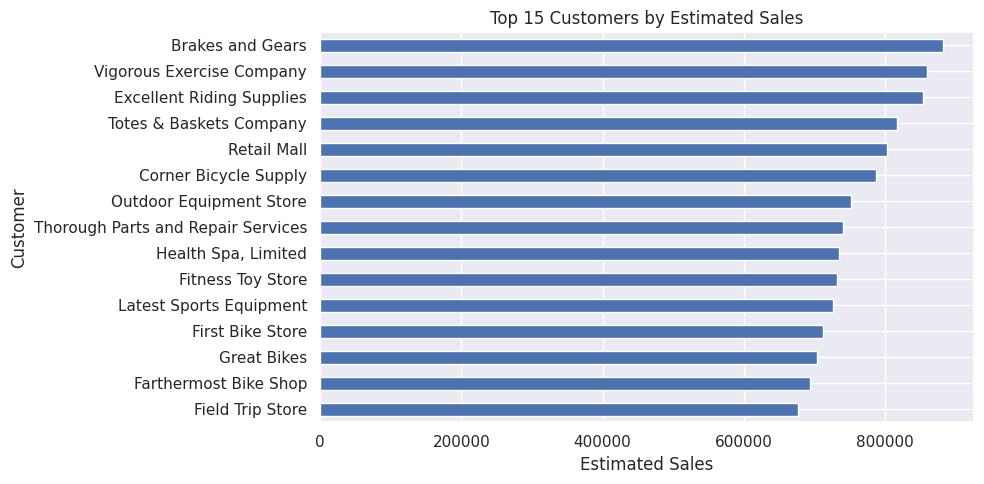

In [14]:
customer_performance = (
    df.groupby("Customer", dropna=False)
      .agg(Estimated_Sales=("Estimated Sales", "sum"),
           Order_Quantity=("OrderQty", "sum"),
           Records=("OrderQty", "size"),
           Average_Unit_Price=("UnitPrice", "mean"))
      .sort_values("Estimated_Sales", ascending=False)
)
display(customer_performance.head(15).round(2))

customer_performance.head(15).sort_values("Estimated_Sales").plot(
    kind="barh", y="Estimated_Sales", legend=False
)
plt.title("Top 15 Customers by Estimated Sales")
plt.xlabel("Estimated Sales")
plt.ylabel("Customer")
plt.tight_layout()
plt.show()

,Estimated_Sales,Order_Quantity,Records,Average_Unit_Price,Average_Discount_Percent
Business Segment,,,,,
Bikes,66827511.81,75063,24826,882.43,42.52
Components,11807764.77,49044,18698,251.38,41.26
Clothing,1801581.16,64569,12293,28.23,40.89
Accessories,577969.28,25840,5102,21.66,41.41


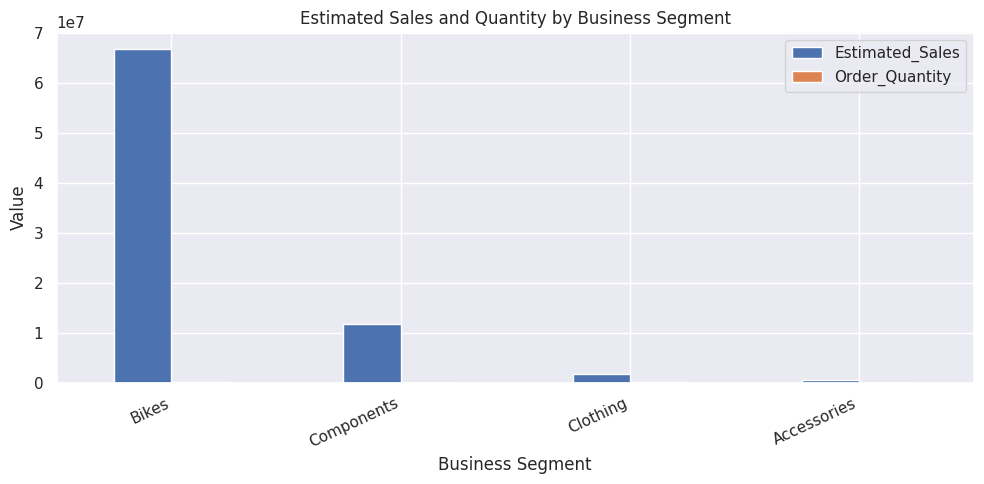

In [15]:
segment_performance = (
    df.groupby("Business Segment", dropna=False)
      .agg(Estimated_Sales=("Estimated Sales", "sum"),
           Order_Quantity=("OrderQty", "sum"),
           Records=("OrderQty", "size"),
           Average_Unit_Price=("UnitPrice", "mean"),
           Average_Discount_Percent=("Discount Percent", "mean"))
      .sort_values("Estimated_Sales", ascending=False)
)
display(segment_performance.round(2))

segment_performance[["Estimated_Sales", "Order_Quantity"]].plot(kind="bar")
plt.title("Estimated Sales and Quantity by Business Segment")
plt.xlabel("Business Segment")
plt.ylabel("Value")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 10. Product, Model & Color Analysis

,Estimated_Sales,Order_Quantity,Records,Average_Unit_Price,Average_Discount_Percent
Category,,,,,
Road Bikes,29457771.63,39128,12876,778.79,42.14
Mountain Bikes,26669470.38,23351,7487,1085.20,43.04
Touring Bikes,10700269.80,12584,4463,841.25,42.76
Mountain Frames,4714719.50,11621,4477,432.33,41.41
Road Frames,3851976.27,11753,4713,335.01,42.83
Touring Frames,1644939.71,3725,1428,425.50,40.02
Wheels,681438.17,5273,1904,127.61,39.98
Jerseys,583661.21,19379,3859,30.13,41.25
Shorts,349066.71,8948,1591,39.44,40.56


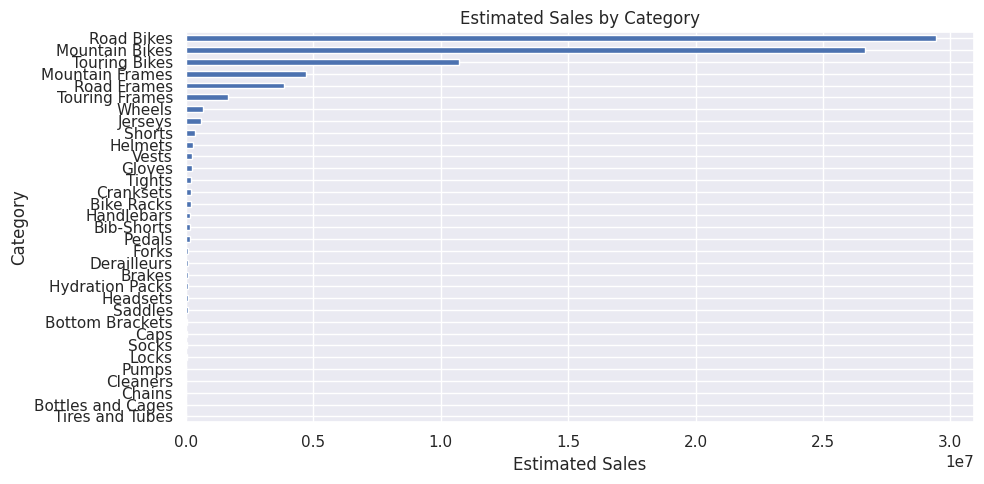

In [16]:
category_performance = (
    df.groupby("Category", dropna=False)
      .agg(Estimated_Sales=("Estimated Sales", "sum"),
           Order_Quantity=("OrderQty", "sum"),
           Records=("OrderQty", "size"),
           Average_Unit_Price=("UnitPrice", "mean"),
           Average_Discount_Percent=("Discount Percent", "mean"))
      .sort_values("Estimated_Sales", ascending=False)
)
display(category_performance.round(2))

category_performance["Estimated_Sales"].sort_values().plot(kind="barh")
plt.title("Estimated Sales by Category")
plt.xlabel("Estimated Sales")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [17]:
model_performance = (
    df.groupby("Model", dropna=False)
      .agg(Estimated_Sales=("Estimated Sales", "sum"),
           Order_Quantity=("OrderQty", "sum"),
           Records=("OrderQty", "size"),
           Average_Unit_Price=("UnitPrice", "mean"),
           Average_Discount_Percent=("Discount Percent", "mean"))
      .sort_values("Estimated_Sales", ascending=False)
)
print("Top 15 models by estimated sales:")
display(model_performance.head(15).round(2))
print("Bottom 15 models by estimated sales:")
display(model_performance.tail(15).sort_values("Estimated_Sales").round(2))

Top 15 models by estimated sales:


,Estimated_Sales,Order_Quantity,Records,Average_Unit_Price,Average_Discount_Percent
Model,,,,,
Mountain-200,14375689.58,11044,3124,1301.72,43.56
Road-250,9386774.15,6684,2248,1408.24,42.36
Mountain-100,8708336.26,4555,1450,1919.94,43.32
Road-650,7507170.79,16757,5358,446.44,42.98
Touring-1000,6889932.42,5097,1725,1365.19,42.74
Road-350-W,3686864.54,3650,997,1018.27,40.14
Road-550-W,3670267.22,5793,1888,636.29,43.21
HL Mountain Frame,3365241.41,4363,1899,769.48,43.33
Road-150,2363802.96,1101,539,2146.96,40.00


Bottom 15 models by estimated sales:


,Estimated_Sales,Order_Quantity,Records,Average_Unit_Price,Average_Discount_Percent
Model,,,,,
LL Road Seat/Saddle 1,162.70,10,6,16.27,40.01
Patch kit,922.90,674,163,1.37,40.19
LL Touring Seat/Saddle,1480.57,91,43,16.27,40.01
LL Touring Handlebars,1548.40,56,30,27.65,40.01
LL Headset,1949.40,95,46,20.52,40.00
ML Touring Seat/Saddle,1972.32,84,41,23.48,40.01
HL Road Seat/Saddle 2,4231.72,134,60,31.58,40.01
LL Road Handlebars,5421.63,213,98,25.60,42.51
LL Mountain Seat/Saddle 2,5639.75,347,153,16.27,40.02


,Estimated_Sales,Order_Quantity,Records
Color,,,
Black,29521621.96,72094,20256
Silver,14753210.05,21599,7230
Yellow,14036890.92,27757,8063
Red,13935674.25,24280,8116
Blue,7382071.53,19689,5074
NaN,667042.68,19370,5226
Multi,545890.17,21147,4576
Silver/Black,147515.15,3931,1517
White,24910.31,4649,861


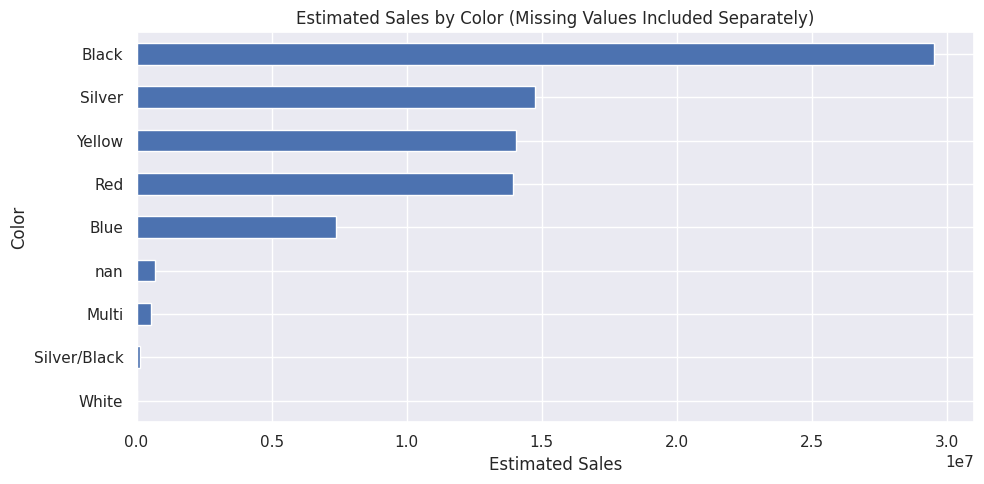

In [18]:
color_performance = (
    df.groupby("Color", dropna=False)
      .agg(Estimated_Sales=("Estimated Sales", "sum"),
           Order_Quantity=("OrderQty", "sum"),
           Records=("OrderQty", "size"))
      .sort_values("Estimated_Sales", ascending=False)
)
display(color_performance.round(2))

color_performance["Estimated_Sales"].sort_values().plot(kind="barh")
plt.title("Estimated Sales by Color (Missing Values Included Separately)")
plt.xlabel("Estimated Sales")
plt.ylabel("Color")
plt.tight_layout()
plt.show()

## 11. Pricing, Discounts, Relationships & Validation

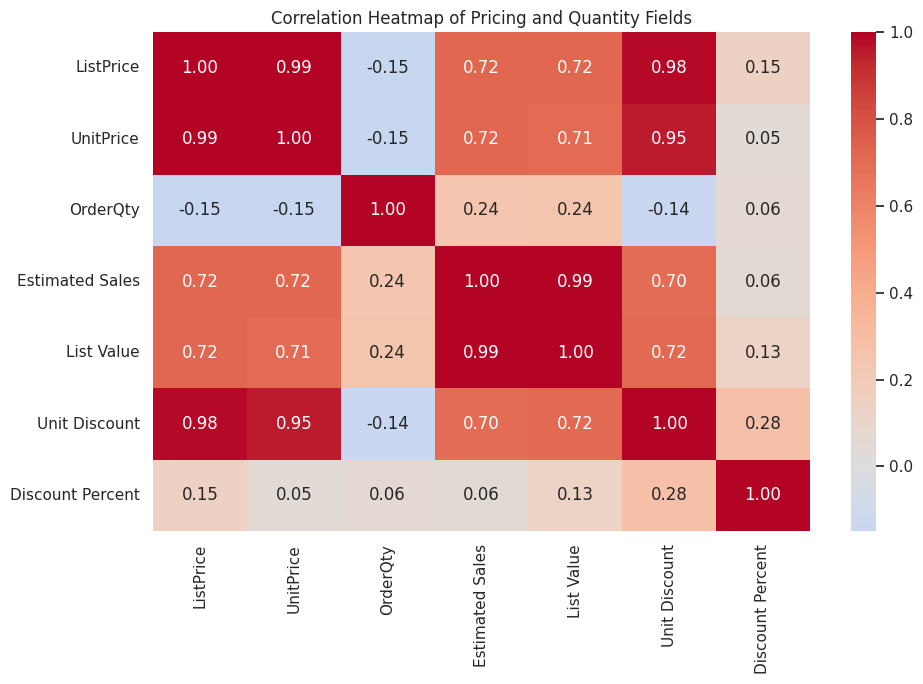

In [19]:
# Price and quantity relationships
numeric_cols = ["ListPrice", "UnitPrice", "OrderQty", "Estimated Sales",
                "List Value", "Unit Discount", "Discount Percent"]
corr = df[numeric_cols].corr(numeric_only=True)

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Pricing and Quantity Fields")
plt.tight_layout()
plt.show()

Discount percentage summary:


,Discount Percent
count,60919.00
mean,41.71
std,4.02
min,26.00
25%,40.00
50%,40.00
75%,42.30
max,80.00


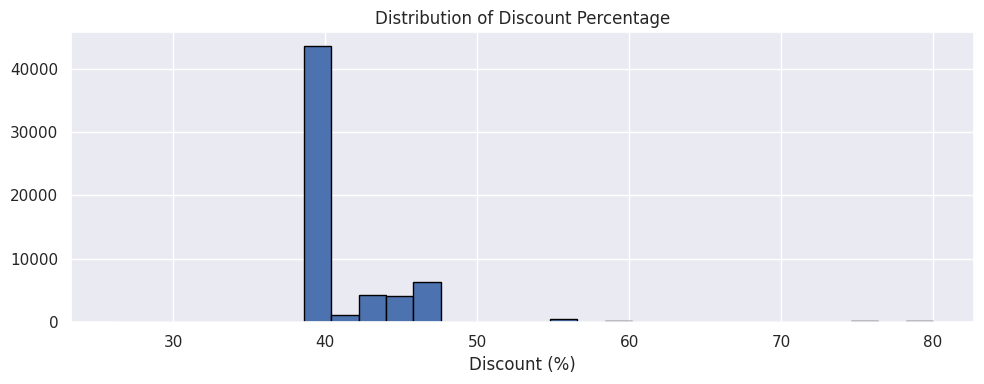

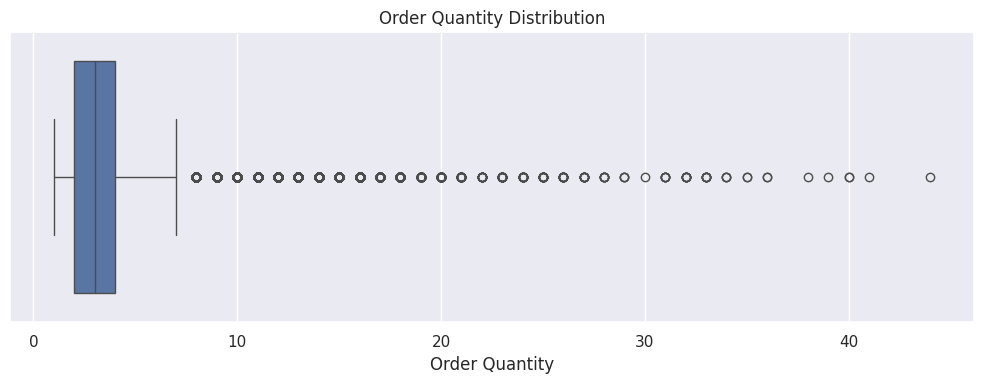

In [20]:
print("Discount percentage summary:")
display(df["Discount Percent"].describe().to_frame("Discount Percent").round(2))

plt.figure(figsize=(10, 4))
plt.hist(df["Discount Percent"].dropna(), bins=30, edgecolor="black")
plt.title("Distribution of Discount Percentage")
plt.xlabel("Discount (%)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
sns.boxplot(x=df["OrderQty"])
plt.title("Order Quantity Distribution")
plt.xlabel("Order Quantity")
plt.tight_layout()
plt.show()

In [21]:
# Data validation checks
validation = pd.Series({
    "Rows where UnitPrice > ListPrice": (df["UnitPrice"] > df["ListPrice"]).sum(),
    "Rows where UnitPrice < 0": (df["UnitPrice"] < 0).sum(),
    "Rows where ListPrice < 0": (df["ListPrice"] < 0).sum(),
    "Rows where OrderQty <= 0": (df["OrderQty"] <= 0).sum(),
    "Rows with missing Color": df["Color"].isna().sum(),
    "Exact duplicate rows": df.duplicated().sum()
})
display(validation.to_frame("Count"))

# Show sample duplicate rows, if present
duplicates = df[df.duplicated(keep=False)]
if not duplicates.empty:
    print("Sample rows participating in exact duplicates:")
    display(duplicates.head(10))

,Count
Rows where UnitPrice > ListPrice,0
Rows where UnitPrice < 0,0
Rows where ListPrice < 0,0
Rows where OrderQty <= 0,0
Rows with missing Color,5226
Exact duplicate rows,34


Sample rows participating in exact duplicates:


,Region,SubRegion,Market,Customer,Business Segment,Category,Model,Color,SalesDate,ListPrice,UnitPrice,OrderQty,Estimated Sales,List Value,Unit Discount,Discount Percent,Year,Quarter,Month Number,Month,Year-Month,Day of Week,Is Weekend
453,North America,United States,Northwest,Outdoor Sports Supply,Bikes,Mountain Bikes,Mountain-100,Black,2020-02-09,3374.99,2024.99,4,8099.96,13499.96,1350.00,40.000119,2020,2020Q1,2,February,2020-02,Sunday,True
660,North America,United States,Northwest,Sure & Reliable Sporting Goods,Bikes,Road Bikes,Road-450,Red,2018-10-30,1457.99,874.79,2,1749.58,2915.98,583.20,40.000274,2018,2018Q4,10,October,2018-10,Tuesday,False
1075,North America,Canada,Canada,Tenth Bike Store,Bikes,Road Bikes,Road-650,Red,2019-08-31,782.99,419.46,2,838.92,1565.98,363.53,46.428435,2019,2019Q3,8,August,2019-08,Saturday,True
1492,North America,United States,Southeast,Excellent Riding Supplies,Bikes,Road Bikes,Road-150,Red,2019-10-21,3578.27,2146.96,2,4293.92,7156.54,1431.31,40.000056,2019,2019Q4,10,October,2019-10,Monday,False
1550,North America,United States,Central,Sample Bike Store,Bikes,Road Bikes,Road-650,Red,2021-04-25,782.99,419.46,1,419.46,782.99,363.53,46.428435,2021,2021Q2,4,April,2021-04,Sunday,True
2484,North America,United States,Northwest,Outdoor Sports Supply,Bikes,Mountain Bikes,Mountain-100,Black,2020-02-09,3374.99,2024.99,4,8099.96,13499.96,1350.00,40.000119,2020,2020Q1,2,February,2020-02,Sunday,True
2758,North America,United States,Northwest,Sure & Reliable Sporting Goods,Bikes,Road Bikes,Road-450,Red,2018-10-30,1457.99,874.79,2,1749.58,2915.98,583.20,40.000274,2018,2018Q4,10,October,2018-10,Tuesday,False
3286,North America,Canada,Canada,Tenth Bike Store,Bikes,Road Bikes,Road-650,Red,2019-08-31,782.99,419.46,2,838.92,1565.98,363.53,46.428435,2019,2019Q3,8,August,2019-08,Saturday,True
3800,North America,United States,Southeast,Excellent Riding Supplies,Bikes,Road Bikes,Road-650,Black,2020-07-11,782.99,419.46,2,838.92,1565.98,363.53,46.428435,2020,2020Q3,7,July,2020-07,Saturday,True
3807,North America,United States,Southeast,Excellent Riding Supplies,Bikes,Road Bikes,Road-150,Red,2019-10-21,3578.27,2146.96,2,4293.92,7156.54,1431.31,40.000056,2019,2019Q4,10,October,2019-10,Monday,False


## 12. Summary & Key Findings

In [22]:
print("DATASET SUMMARY")
print("-" * 55)
print(f"Records: {len(df):,}")
print(f"Original columns: 12")
print(f"Date range: {df['SalesDate'].min().date()} to {df['SalesDate'].max().date()}")
print(f"Unique customers: {df['Customer'].nunique():,}")
print(f"Unique product models: {df['Model'].nunique():,}")
print(f"Total order quantity: {df['OrderQty'].sum():,.0f}")
print(f"Estimated sales (UnitPrice × OrderQty): {df['Estimated Sales'].sum():,.2f}")
print(f"Estimated discount value: {df['Unit Discount'].mul(df['OrderQty']).sum():,.2f}")
print(f"Missing Color values: {df['Color'].isna().sum():,}")
print(f"Exact duplicate rows: {df.duplicated().sum():,}")

print("\\nTop categories by estimated sales:")
display(category_performance.head(5).round(2))
print("\\nTop regions by estimated sales:")
display(df.groupby("Region")["Estimated Sales"].sum().sort_values(ascending=False).head(5).to_frame("Estimated Sales").round(2))
print("\\nTop customers by estimated sales:")
display(customer_performance.head(5).round(2))

print("\\nInterpretation note: Estimated Sales is calculated from UnitPrice × OrderQty. Review the tables and charts to identify the strongest categories, models, customers, regions, and date trends.")

DATASET SUMMARY
-------------------------------------------------------
Records: 60,919
Original columns: 12
Date range: 2018-06-18 to 2024-02-26
Unique customers: 633
Unique product models: 93
Total order quantity: 214,516
Estimated sales (UnitPrice × OrderQty): 81,014,827.02
Estimated discount value: 60,062,467.53
Missing Color values: 5,226
Exact duplicate rows: 34
\nTop categories by estimated sales:


,Estimated_Sales,Order_Quantity,Records,Average_Unit_Price,Average_Discount_Percent
Category,,,,,
Road Bikes,29457771.63,39128,12876,778.79,42.14
Mountain Bikes,26669470.38,23351,7487,1085.20,43.04
Touring Bikes,10700269.80,12584,4463,841.25,42.76
Mountain Frames,4714719.50,11621,4477,432.33,41.41
Road Frames,3851976.27,11753,4713,335.01,42.83


\nTop regions by estimated sales:


,Estimated Sales
Region,
North America,68381907.94
Europe,11010058.46
Pacific,1622860.62


\nTop customers by estimated sales:


,Estimated_Sales,Order_Quantity,Records,Average_Unit_Price
Customer,,,,
Brakes and Gears,882273.53,1558,298,563.29
Vigorous Exercise Company,860142.25,2737,530,373.58
Excellent Riding Supplies,853848.29,1322,366,632.39
Totes & Baskets Company,817125.03,1736,436,517.16
Retail Mall,803767.27,1931,451,420.34


\nInterpretation note: Estimated Sales is calculated from UnitPrice × OrderQty. Review the tables and charts to identify the strongest categories, models, customers, regions, and date trends.
